NAME: Anna Bernardi (coded together with Liam Kniberg)

DATE: September 2025

This notebook's aim is to present a model for Poisson regression with year as predictor and as the bird counts as the response variable

# Code requirements

In [97]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# Loading the data 

In [98]:
df = pd.read_csv('bird_count.csv')
display(df)

,count,yr,observerAge,lineCov
0,2,2011,63,1.000000
1,5,2010,64,0.987500
2,12,2002,30,0.991667
3,12,2006,60,0.987500
4,5,2008,62,0.987500
5,12,2012,64,1.000000
6,5,2000,28,0.991667
7,8,2005,59,0.987500
8,9,2007,61,0.987500
9,14,2004,58,1.000000


In [104]:
df.sort_values(by=['yr'], inplace=True)
df

,count,yr,observerAge,lineCov
10,10,1999,27,0.991667
6,5,2000,28,0.991667
11,9,2001,29,0.991667
2,12,2002,30,0.991667
9,14,2004,58,1.000000
7,8,2005,59,0.987500
3,12,2006,60,0.987500
8,9,2007,61,0.987500
4,5,2008,62,0.987500
12,5,2009,63,0.987500


Text(0.5, 1.0, 'Bird count per year')

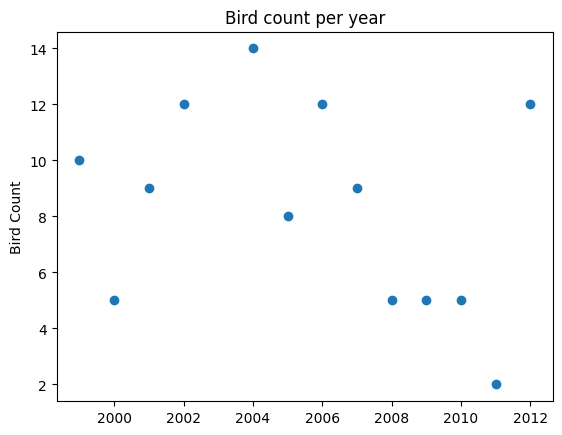

In [100]:
plt.scatter(df['yr'],df['count'])
plt.ylabel('Bird Count')
plt.title("Bird count per year")

# Poisson Regression
In the case of our data let :

Y: total bird counts; 

X: years

If Y follows the Poisson ditribution $Y|x_i \sim Po(\lambda (x_i))$ then: 
$$Pr(Y=k) = \frac{\exp(- \lambda )\lambda ^k}{k!}$$

Where $\lambda$ is equal to the expected value and the variance of Y.

We allow the $\lambda$ to vary as a function of the covarietes:
$$\lambda (X_1,...,X_p) = \exp(\beta _0 + \beta _1 X_1 + ... + \beta _p X_p)$$

Or the equivalent log version: 
$$\log(\lambda (X_1,...,X_p) )= \beta _0 + \beta _1 X_1 + ... + \beta _p X_p$$


# Maximum likelihood estimation

Need to find the parameter values that maximixes the log of the likelihood function:

$$\hat\theta = argmax\log(l(\theta))$$

The log likelihood function for the Poisson GLM is 

$$\log(l(y|\beta _0,\beta _1, x)) = \sum_{i=1}^n [-\lambda(x_i)+y_ilog(\lambda(x_i))-\log(y_i!)]$$

With $\lambda(x_i)=\exp(\beta _0+\beta _1x_i )=E(Y|x_i)$

Since $y_i$ doesn't depend on the parameters it can be dropped 
$$\log(l(y|\beta _0,\beta _1, x)) = \sum_{i=1}^n [-\lambda(x_i)+y_ilog(\lambda(x_i))]$$

To find the maximum we derive with respect to $\theta$ the parameters
$\frac{\partial log(l(y|\theta,x)) }{\partial \theta}=0$

But here is no closed-form solution so the parameters must be found numerically

In [101]:
def log_likelihood(params,x,y):
    beta_0, beta_1 = params

    lambda_hat = beta_0 + beta_1 * x
    
    #clipping to avoid exp overflow
    lambda_hat = np.clip(lambda_hat, -500, 500)
    
    result = np.sum(y * lambda_hat - np.exp(lambda_hat))
    
    return result


# Maximizing the likelihood

In [109]:
x = df['yr'].to_numpy()
y = df['count'].to_numpy()

x_norm = x - 1999   #because it was overflowing; x = [0,...,13]

#initial guess
init = np.array([0.0, 0.0])

res = minimize(lambda p: -log_likelihood(p, x_norm, y), init)  #to maximize the function I'm minimizing the -log likelihood
beta0_hat, beta1_hat = res.x


print("The parameters after the optimazation are: beta_0:", np.round(beta0_hat, 3), "; beta_1:", np.round(beta1_hat, 3))


The parameters after the optimazation are: beta_0: 2.325 ; beta_1: -0.032


# Hypothetical observations

I'll now generate three samples of data using the estimated parameters. 

In [110]:
x = x_norm[0:3]
lamba = []
for i in range(len(x)):
    lambda_hat = np.exp(beta0_hat + beta1_hat * x[i])
    lamba.append(lambda_hat)
    print("The estimated value of the bird count for the year", np.round(x_norm[i]+1999, 3), "is ", np.round(lamba[i],3))


The estimated value of the bird count for the year 1999 is  10.23
The estimated value of the bird count for the year 2000 is  9.904
The estimated value of the bird count for the year 2001 is  9.587
